# 10. Quadrature: integrating with spectral accuracy

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/10_quadrature.ipynb)

*Companion to Chapter 12 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Engineers integrate computed profiles all the time: a velocity profile gives a flow rate, a
heat flux gives a duty, a pressure distribution gives a force. Spectral differentiation came
from differentiating an interpolant. Spectral integration comes from **integrating** the same
interpolant, and it inherits the same accuracy: errors that fall geometrically for smooth
integrands.

- why the plain trapezoidal rule is a spectral method for periodic integrands
- Clenshaw-Curtis weights for the Chebyshev points, and Gauss-Legendre quadrature
- how the two compare, and what a singularity does to both
- other intervals, two dimensions and indefinite integrals

**Worked examples:** flow rate, bulk temperature and Nusselt number in a tube; the flow rate of
a Carreau-Yasuda fluid, compared with a published value.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct
from scipy.linalg import eigh_tridiagonal
from scipy.integrate import quad
from scipy.optimize import brentq
from scipy.special import ellipe, ellipeinc, erf, j0

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 10.1 Periodic integrands: the trapezoidal rule is spectral

**Problem.** Find the perimeter of an ellipse with semi-axes $a = 1$ and $b = \tfrac12$,

$$P = \int_0^{2\pi}\sqrt{a^2\sin^2t + b^2\cos^2t}\;dt .$$

There is no elementary formula. The exact value is $4a\,E(1 - b^2/a^2) = 4.8442241\ldots$,
where $E$ is the complete elliptic integral of the second kind.

**By hand.** On a periodic grid $t_j = 2\pi j/N$ the two end points of the trapezoidal rule
coincide, and the rule reduces to $h\sum_j f(t_j)$ with $h = 2\pi/N$: the mean of the samples
times the length of the period. Apply it to one Fourier mode $e^{ikt}$. The sum
$\sum_j e^{2\pi ijk/N}$ is a geometric series that vanishes unless $k$ is a multiple of $N$, so
the rule integrates every mode with $|k| < N$ **exactly**. The error consists only of the
Fourier coefficients $c_{\pm N}, c_{\pm 2N}, \dots$ of the integrand, and for an analytic
periodic function those are geometrically small (notebook 3). Put another way: the rule
integrates the trigonometric interpolant of notebook 2 exactly.

If the interval is not a full period the argument fails and the familiar $O(h^2)$ error
returns. The arc of the same ellipse from $t = 0$ to $t = 1$ shows it.

perimeter with N = 48: 4.8442241102738   exact: 4.8442241102738
error with N = 48:  perimeter 7.6e-14   arc 1.4e-05


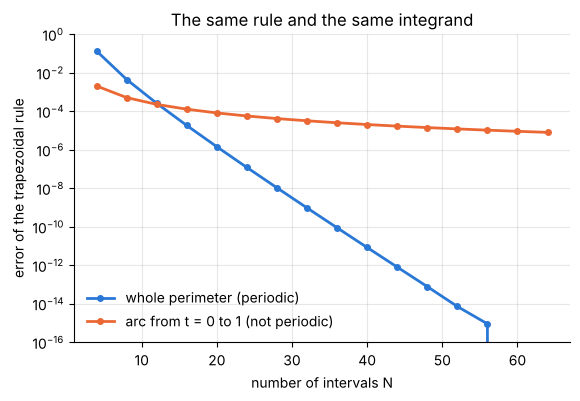

In [2]:
a_ell, b_ell = 1.0, 0.5
arc_speed = lambda t: np.sqrt(a_ell**2 * np.sin(t) ** 2 + b_ell**2 * np.cos(t) ** 2)
perimeter_exact = 4 * a_ell * ellipe(1 - b_ell**2 / a_ell**2)
arc_exact = b_ell * ellipeinc(1.0, 1 - a_ell**2 / b_ell**2)       # arc from t = 0 to t = 1, an incomplete elliptic integral

def periodic_trapezoid(f, N, period=2 * np.pi):
    """Trapezoidal rule over one period: the period times the mean of N equally spaced samples."""
    return period * np.mean(f(period * np.arange(N) / N))

N_values = np.arange(4, 65, 4)
error_full = np.array([abs(periodic_trapezoid(arc_speed, N) - perimeter_exact) for N in N_values])
error_arc = np.array([abs(np.trapezoid(arc_speed(np.linspace(0, 1, N + 1)), dx=1 / N) - arc_exact) for N in N_values])

print(f"perimeter with N = 48: {periodic_trapezoid(arc_speed, 48):.13f}   exact: {perimeter_exact:.13f}")
print(f"error with N = 48:  perimeter {error_full[N_values == 48][0]:.1e}   arc {error_arc[N_values == 48][0]:.1e}")
fig, ax = plt.subplots()
ax.semilogy(N_values, error_full, "o-", ms=4, label="whole perimeter (periodic)")
ax.semilogy(N_values, error_arc, "o-", ms=4, label="arc from t = 0 to 1 (not periodic)")
ax.set(xlabel="number of intervals N", ylabel="error of the trapezoidal rule", ylim=(1e-16, 1),
       title="The same rule and the same integrand")
ax.legend(frameon=False, loc="lower left");

**Verify** the two rates. For the arc, the order must be 2. For the whole perimeter, the
integrand has branch points where the square root vanishes, at $\tan t = \pm ib/a$, a distance
$\operatorname{artanh}(b/a) = \tfrac12\ln 3$ from the real axis. Its Fourier coefficients decay
like $k^{-3/2}e^{-k\ln3/2}$, so the error should behave like $N^{-3/2}\,3^{-N/2}$.

In [3]:
order_arc = np.log2(error_arc[N_values == 16][0] / error_arc[N_values == 32][0])
window = (N_values >= 8) & (N_values <= 48)
rate = -np.polyfit(N_values[window], np.log(error_full[window] * N_values[window] ** 1.5), 1)[0]
print(f"arc: observed order {order_arc:.2f}        perimeter: error ∝ exp(-{rate:.3f} N), predicted exp(-{np.log(3) / 2:.3f} N)")
assert abs(order_arc - 2) < 0.05
assert abs(rate / (np.log(3) / 2) - 1) < 0.05
assert abs(periodic_trapezoid(arc_speed, 64) - 4.8442241) < 1e-7 and error_full[-1] < 1e-13

arc: observed order 2.00        perimeter: error ∝ exp(-0.551 N), predicted exp(-0.549 N)


With 48 points the perimeter is correct to thirteen digits, where the same rule on the open arc
has four. Integrals over a closed curve or a full cycle (the mean of a signal over a period,
the circulation round a contour, the average over a crank revolution) should always be
computed with equally spaced points and equal weights. Nothing more elaborate does better.

A second example: Bessel's integral $J_0(x) = \dfrac1\pi\displaystyle\int_0^\pi\cos(x\sin t)\,dt$.
The integrand has period $\pi$ and no singularities at all, so convergence is faster than
geometric once $N$ is large enough to sample the oscillations.

In [4]:
print("error of the N-point trapezoidal rule for J0(x)")
print("    x     N = 4      N = 8     N = 16     N = 32")
for x_bessel in (1.0, 5.0, 20.0):
    integrand = lambda t: np.cos(x_bessel * np.sin(t)) / np.pi
    errors = [abs(periodic_trapezoid(integrand, N, period=np.pi) - j0(x_bessel)) for N in (4, 8, 16, 32)]
    print(f"{x_bessel:5.0f} " + "".join(f"{e:11.1e}" for e in errors))
    assert errors[-1] < 1e-14

error of the N-point trapezoidal rule for J0(x)
    x     N = 4      N = 8     N = 16     N = 32
    1     1.9e-07    0.0e+00    0.0e+00    0.0e+00
    5     3.7e-02    1.5e-07    0.0e+00    2.8e-17
   20     1.8e-01    2.9e-01    3.1e-05    2.8e-17


## 10.2 Clenshaw-Curtis quadrature

**Problem.** Integrate a function that is **not** periodic over $[-1, 1]$, from its values at
the Chebyshev points $x_j = \cos(j\pi/N)$.

**By hand.** Integrate the polynomial interpolant $p$. In coefficient form (notebook 7),
$p = \sum_k a_kT_k$, and the integrals of the Chebyshev polynomials are known: with
$x = \cos\theta$,

$$m_k = \int_{-1}^{1}T_k(x)\,dx = \int_0^\pi\cos k\theta\,\sin\theta\,d\theta =
\begin{cases} \dfrac{2}{1-k^2}, & k \text{ even},\\[1ex] 0, & k \text{ odd}. \end{cases}$$

So $\int p = \sum_k m_ka_k$. The coefficients are a linear function of the values, a discrete
cosine transform, $\mathbf{a} = C\mathbf{v}$. Hence
$\int p = \mathbf{m}^TC\mathbf{v} = (C^T\mathbf{m})^T\mathbf{v}$: the integral is a weighted
sum of the values with weights $\mathbf{w} = C^T\mathbf{m}$. The transform is its own
transpose apart from the factors of one half at the two ends, so the weights are obtained by
applying the same cosine transform to the moments $m_k$. All $N + 1$ weights cost one FFT.

In [5]:
def clenshaw_curtis(N):
    """Clenshaw-Curtis nodes (the Chebyshev points) and weights on [-1, 1]."""
    if N == 0:
        return np.ones(1), np.array([2.0])
    x = np.cos(np.pi * np.arange(N + 1) / N)
    moments = np.zeros(N + 1)
    even = np.arange(0, N + 1, 2)
    moments[even] = 2 / (1 - even.astype(float) ** 2)             # integrals of T_k; zero for odd k
    w = dct(moments, type=1) / N                                   # cosine transform of the moments
    w[0] /= 2
    w[N] /= 2
    return x, w

def monomial_integral(d):                                          # exact integral of x^d over [-1, 1]
    return 2 / (d + 1) if d % 2 == 0 else 0.0

**Verify.** The weights must add up to 2, the length of the interval. With $N = 2$ the rule
must be Simpson's rule, the integral of the parabola through three equally spaced points. And
every polynomial of degree up to $N$ must be integrated exactly.

In [6]:
assert np.allclose(clenshaw_curtis(2)[1], [1 / 3, 4 / 3, 1 / 3], rtol=0, atol=1e-15)
for N in (1, 4, 9, 16, 33):
    x, w = clenshaw_curtis(N)
    assert abs(w.sum() - 2) < 1e-14 and (w > 0).all()
    assert all(abs(w @ x**d - monomial_integral(d)) < 1e-14 for d in range(N + 1))
x, w = clenshaw_curtis(8)
print("N = 8 weights:", np.round(w, 4))
print(f"degree 10 with N = 8: error {abs(w @ x**10 - monomial_integral(10)):.1e}  (beyond the guaranteed degree, not exact)")
assert abs(w @ x**10 - monomial_integral(10)) > 1e-6

N = 8 weights: [0.0159 0.1462 0.2794 0.3617 0.3937 0.3617 0.2794 0.1462 0.0159]
degree 10 with N = 8: error 7.2e-05  (beyond the guaranteed degree, not exact)


The weights are all positive, which keeps the rule stable, and small at the ends, where the
points are crowded.

## 10.3 Gauss-Legendre quadrature

Clenshaw-Curtis fixes the nodes and chooses $N + 1$ weights, which is enough to be exact up to
degree $N$. Gauss quadrature chooses the $n$ nodes as well, $2n$ free numbers in all, and is
exact up to degree $2n - 1$, the highest possible. The nodes turn out to be the roots of the
Legendre polynomial $P_n$, the polynomial of degree $n$ that is orthogonal on $[-1, 1]$ to
every polynomial of lower degree.

**By hand.** The Legendre polynomials satisfy a three-term recurrence. Written for the
normalized polynomials $\tilde P_k$ it reads
$x\tilde P_k = \beta_k\tilde P_{k-1} + \beta_{k+1}\tilde P_{k+1}$ with
$\beta_k = k/\sqrt{4k^2 - 1}$. Stack these equations for $k = 0, \dots, n-1$: they say that
$x$ times the vector $(\tilde P_0(x), \dots, \tilde P_{n-1}(x))$ equals a symmetric tridiagonal
matrix $J$ times the same vector, plus a remainder proportional to $\tilde P_n(x)$. At a root
of $P_n$ the remainder vanishes. So the nodes are the **eigenvalues** of $J$, and it can be
shown that each weight is twice the square of the first component of the corresponding unit
eigenvector. This is the Golub-Welsch method.

In [7]:
def gauss_legendre(n):
    """Gauss-Legendre nodes and weights (n points) by the Golub-Welsch eigenvalue method."""
    k = np.arange(1, n)
    beta = k / np.sqrt(4.0 * k**2 - 1)
    nodes, vectors = eigh_tridiagonal(np.zeros(n), beta)
    return nodes, 2 * vectors[0] ** 2

**Verify** against NumPy's tabulated rule and test the degree of exactness: $2n - 1$ and no
higher.

In [8]:
for n in (1, 2, 5, 16, 40):
    nodes, weights = gauss_legendre(n)
    reference_nodes, reference_weights = np.polynomial.legendre.leggauss(n)
    assert np.allclose(nodes, reference_nodes, rtol=0, atol=1e-13) and np.allclose(weights, reference_weights, rtol=0, atol=1e-13)
    assert all(abs(weights @ nodes**d - monomial_integral(d)) < 1e-13 for d in range(2 * n))
nodes, weights = gauss_legendre(5)
print(f"n = 5: degree 9 error {abs(weights @ nodes**9 - monomial_integral(9)):.1e},  degree 10 error {abs(weights @ nodes**10 - monomial_integral(10)):.1e}")
assert abs(weights @ nodes**10 - monomial_integral(10)) > 1e-4

n = 5: degree 9 error 9.5e-17,  degree 10 error 2.9e-03


## 10.4 Which rule is better?

Compare the two rules with the same number of points on the four test functions of notebook 5.

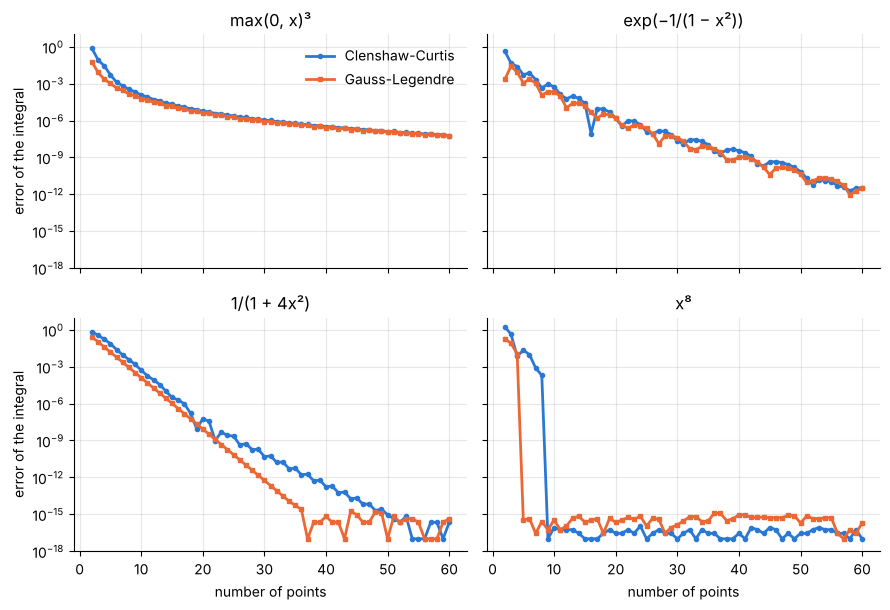

In [9]:
def bump(x):
    inside = np.abs(x) < 1
    safe = np.where(inside, 1 - x**2, 1.0)
    return np.where(inside, np.exp(-1 / safe), 0.0)

bump_integral = quad(lambda x: np.exp(-1 / (1 - x**2)), -1, 1, epsabs=1e-14, epsrel=1e-14)[0]
tests = {
    "max(0, x)³": (lambda x: np.maximum(0, x) ** 3, 1 / 4),
    "exp(−1/(1 − x²))": (bump, bump_integral),
    "1/(1 + 4x²)": (lambda x: 1 / (1 + 4 * x**2), np.arctan(2.0)),
    "x⁸": (lambda x: x**8, 2 / 9),
}

def cc_error(f, exact, n):                                         # n points means N = n - 1
    x, w = clenshaw_curtis(n - 1)
    return abs(w @ f(x) - exact)

def gauss_error(f, exact, n):
    x, w = gauss_legendre(n)
    return abs(w @ f(x) - exact)

points = np.arange(2, 61)
fig, axes = plt.subplots(2, 2, figsize=(9, 6.2), sharex=True, sharey=True)
comparison = {}
for ax, (name, (f, exact)) in zip(axes.flat, tests.items()):
    comparison[name] = (np.array([cc_error(f, exact, n) for n in points]), np.array([gauss_error(f, exact, n) for n in points]))
    ax.semilogy(points, np.maximum(comparison[name][0], 1e-17), "o-", ms=3, label="Clenshaw-Curtis")
    ax.semilogy(points, np.maximum(comparison[name][1], 1e-17), "s-", ms=3, label="Gauss-Legendre")
    ax.set(title=name, ylim=(1e-18, 10))
axes[0, 0].legend(frameon=False, loc="upper right")
for ax in axes[1]:
    ax.set_xlabel("number of points")
for ax in axes[:, 0]:
    ax.set_ylabel("error of the integral")
fig.tight_layout()

In [10]:
print("points needed for an error below 1e-10      Clenshaw-Curtis    Gauss-Legendre")
first_below = lambda errors: int(points[np.argmax(errors < 1e-10)]) if (errors < 1e-10).any() else None
needed = {name: (first_below(cc), first_below(gauss)) for name, (cc, gauss) in comparison.items()}
for name, (n_cc, n_gauss) in needed.items():
    print(f"{name:>32s} {str(n_cc):>20s} {str(n_gauss):>17s}")
assert needed["x⁸"] == (9, 5)                                      # degree 8 needs N = 8, or n = 5 Gauss points
assert needed["1/(1 + 4x²)"][0] <= 1.5 * needed["1/(1 + 4x²)"][1]
assert needed["exp(−1/(1 − x²))"][0] <= 1.3 * needed["exp(−1/(1 − x²))"][1]

points needed for an error below 1e-10      Clenshaw-Curtis    Gauss-Legendre
                      max(0, x)³                 None              None
                exp(−1/(1 − x²))                   50                45
                     1/(1 + 4x²)                   30                25
                              x⁸                    9                 5


For the polynomial, Gauss wins by the factor of two that its degree of exactness promises: 5
points against 9. For the functions that are **not** polynomials the two rules are much
closer than that. For the rough function $\max(0,x)^3$ and for the infinitely differentiable
bump the two curves can hardly be told apart. For the analytic function $1/(1+4x^2)$
Clenshaw-Curtis keeps pace with Gauss down to an error of about $10^{-8}$ and then continues at
about half the rate, needing 30 points against 25 at $10^{-10}$, not 50. The factor-of-two
argument is about polynomials. For other functions the error depends on how well the
interpolant approximates them, and for integrands of limited smoothness, or at moderate
accuracy, the two point sets are nearly equivalent. Only for analytic integrands at high
accuracy does Gauss pull ahead.

The practical conclusion: if the function values are already known at the Chebyshev points, as
they are in every Chebyshev spectral computation, integrate with Clenshaw-Curtis weights and
do not interpolate to Gauss points. If the integrand can be evaluated anywhere, either rule
will do.

## 10.5 Other intervals and two dimensions

For an interval $[a, b]$ map the nodes linearly, $x = a + (b-a)(\xi+1)/2$, and multiply the
weights by $(b-a)/2$. For a rectangle use the rule in each direction: the weight of the point
$(x_j, y_i)$ is the product $w_iw_j$, so the double integral is $\mathbf{w}_y^TF\,\mathbf{w}_x$
for the array of values $F_{ij} = f(x_j, y_i)$.

In [11]:
def cc_on(N, a, b):
    """Clenshaw-Curtis nodes and weights mapped from [-1, 1] to [a, b]."""
    x, w = clenshaw_curtis(N)
    return a + (b - a) * (x + 1) / 2, w * (b - a) / 2

x, wx = cc_on(16, 0.0, 1.0)
y, wy = cc_on(20, 0.0, 2.0)
X, Y = np.meshgrid(x, y)                                           # F[i, j] = f(x_j, y_i)
double_integral = wy @ np.exp(-X**2 - Y**2) @ wx
exact = np.pi / 4 * erf(1.0) * erf(2.0)
print(f"integral of exp(-x² - y²) over [0, 1] x [0, 2]: {double_integral:.14f}   exact: {exact:.14f}")
assert abs(double_integral - exact) < 1e-13

integral of exp(-x² - y²) over [0, 1] x [0, 2]: 0.65875966972613   exact: 0.65875966972612


## 10.6 Indefinite integrals

**Problem.** Sometimes the whole running integral $u(x) = \int_{-1}^{x}f(s)\,ds$ is wanted,
not only its final value: the distance covered from a velocity record, the cumulative heat
release along a reactor.

**By hand.** The running integral is the solution of the differential equation $u' = f$ with
$u(-1) = 0$. Write $D\mathbf{u} = \mathbf{f}$ at every grid point and replace one equation by
the boundary condition, as for the hanging chain of notebook 8. The point $x = -1$ is
**index $N$**, the last one, so the last row of the system becomes $u_N = 0$. The sample
$f(-1)$ is then not used: the result is the exact integral of the polynomial of degree $N - 1$
through the other $N$ samples.

In [12]:
# cheb(N) from notebook 5
def cheb(N):
    """Chebyshev differentiation matrix D, (N+1) x (N+1), and the points x_j = cos(jπ/N)."""
    if N == 0:
        return np.zeros((1, 1)), np.ones(1)
    j = np.arange(N + 1)
    x = np.cos(np.pi * j / N)
    c = np.where((j == 0) | (j == N), 2.0, 1.0) * (-1.0) ** j
    dx = x[:, None] - x[None, :]
    D = (c[:, None] / c[None, :]) / (dx + np.eye(N + 1))        # the identity avoids 0/0 on the diagonal
    D -= np.diag(D.sum(axis=1))                                  # diagonal from the zero row sums
    return D, x

def running_integral(f_values):
    """Running integral from -1 to each Chebyshev point: solves u' = f at all points but x = -1, where u = 0."""
    N = len(f_values) - 1
    A = cheb(N)[0]
    A[N, :] = 0.0
    A[N, N] = 1.0                                                  # last row: the condition u(-1) = 0
    rhs = np.array(f_values, dtype=float)
    rhs[N] = 0.0
    return np.linalg.solve(A, rhs)

**Verify** on the Gaussian, whose running integral is the error function:
$\int_{-1}^{x}\tfrac{2}{\sqrt\pi}e^{-s^2}ds = \operatorname{erf}(x) + \operatorname{erf}(1)$.
The value at $x = +1$, which is index 0, must also agree with the Clenshaw-Curtis rule to
rounding, because the Gaussian is fully resolved on this grid. On a coarse grid the two differ
slightly, since Clenshaw-Curtis integrates the interpolant of degree $N$ through all the
samples.

In [13]:
N = 24
x, w = clenshaw_curtis(N)
gaussian = 2 / np.sqrt(np.pi) * np.exp(-x**2)
u = running_integral(gaussian)
print(f"largest error against erf(x) + erf(1): {np.abs(u - (erf(x) + erf(1.0))).max():.1e}")
assert np.abs(u - (erf(x) + erf(1.0))).max() < 1e-13
assert abs(u[0] - w @ gaussian) < 1e-13

x_coarse, w_coarse = clenshaw_curtis(8)
coarse = 2 / np.sqrt(np.pi) * np.exp(-x_coarse**2)
difference = abs(running_integral(coarse)[0] - w_coarse @ coarse)
print(f"N = 8: the two values of the whole integral differ by {difference:.1e}")
assert 1e-5 < difference < 1e-4

largest error against erf(x) + erf(1): 1.6e-15
N = 8: the two values of the whole integral differ by 5.7e-05


Twenty-five samples of the Gaussian give the error function to thirteen digits at every grid
point, and between them by interpolation.

## 10.7 Worked example: flow rate and bulk temperature in a tube

**Problem.** A velocity profile $u(r)$ and a temperature profile $T(r)$ are known across a
tube of radius $R$. Find the mean velocity and the mixing-cup (bulk) temperature,

$$\bar u = \frac{2}{R^2}\int_0^R u\,r\,dr,\qquad T_b = \frac{\int_0^R u\,T\,r\,dr}{\int_0^R u\,r\,dr} .$$

**Laminar flow.** With $r$ scaled by $R$, fully developed laminar flow heated by a uniform wall
flux has $u/u_{\max} = 1 - r^2$ and
$\theta = (T_w - T)/(T_w - T_c) = 1 - \tfrac43r^2 + \tfrac13r^4$ (the classical solution, with
$T_c$ the centreline temperature). Both integrands are polynomials, so Clenshaw-Curtis is exact
with a handful of points. The heat transfer coefficient is defined with the bulk temperature,
and the wall gradient $\theta'(1) = -\tfrac43$ gives the Nusselt number
$Nu = hD/k = \tfrac83/\theta_b$.

In [14]:
r, w = cc_on(8, 0.0, 1.0)
u_laminar = 1 - r**2
theta = 1 - 4 / 3 * r**2 + r**4 / 3
mean_over_max = 2 * w @ (u_laminar * r)
theta_bulk = w @ (u_laminar * theta * r) / (w @ (u_laminar * r))
print(f"mean / maximum velocity = {mean_over_max:.12f}    θ_b = {theta_bulk:.12f}    Nu = {8 / 3 / theta_bulk:.10f}")
assert abs(mean_over_max - 1 / 2) < 1e-14 and abs(theta_bulk - 11 / 18) < 1e-14
assert abs(8 / 3 / theta_bulk - 48 / 11) < 1e-13

mean / maximum velocity = 0.500000000000    θ_b = 0.611111111111    Nu = 4.3636363636


Nine points reproduce the textbook results exactly: the mean velocity is half the maximum, and
$Nu = 48/11 = 4.364$.

**Turbulent flow.** A common empirical profile for turbulent pipe flow is the one-seventh power
law, $u/u_{\max} = (1 - r)^{1/7}$, for which $\bar u/u_{\max} = 49/60$ exactly. This integrand
is not smooth: its slope is infinite at the wall. A singularity $(1-r)^\alpha$ at an end point
reduces Clenshaw-Curtis (and Gauss) to algebraic convergence, with an error of order
$N^{-2\alpha-2}$.

**By hand.** The cure is a change of variable that removes the singularity. Put
$1 - r = t^7$. Then $u = t$, $dr = -7t^6\,dt$, and

$$\frac{\bar u}{u_{\max}} = 2\int_0^1(1-r)^{1/7}\,r\,dr = 2\int_0^1 t\,(1 - t^7)\,7t^6\,dt ,$$

a polynomial of degree 14 in $t$, which the rule integrates exactly as soon as $N \ge 14$.

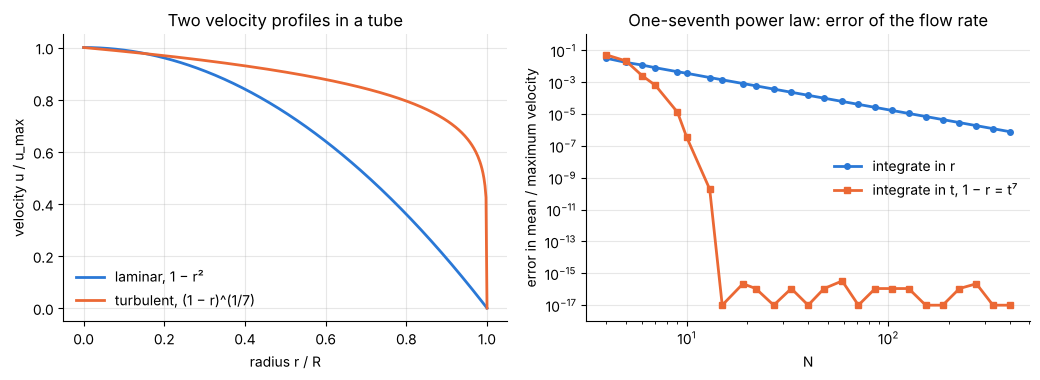

In [15]:
N_values = np.unique(np.round(np.geomspace(4, 400, 25)).astype(int))
direct, substituted = [], []
for N in N_values:
    r, w = cc_on(N, 0.0, 1.0)
    direct.append(abs(2 * w @ ((1 - r) ** (1 / 7) * r) - 49 / 60))
    t = r                                                          # the same nodes, now read as values of t
    substituted.append(abs(2 * w @ (t * (1 - t**7) * 7 * t**6) - 49 / 60))
direct, substituted = np.array(direct), np.array(substituted)

fine = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].plot(fine, 1 - fine**2, label="laminar, 1 − r²")
axes[0].plot(fine, (1 - fine) ** (1 / 7), label="turbulent, (1 − r)^(1/7)")
axes[0].set(xlabel="radius r / R", ylabel="velocity u / u_max", title="Two velocity profiles in a tube")
axes[0].legend(frameon=False, loc="lower left")
axes[1].loglog(N_values, direct, "o-", ms=4, label="integrate in r")
axes[1].loglog(N_values, np.maximum(substituted, 1e-17), "s-", ms=4, label="integrate in t, 1 − r = t⁷")
axes[1].set(xlabel="N", ylabel="error in mean / maximum velocity", ylim=(1e-18, 1), title="One-seventh power law: error of the flow rate")
axes[1].legend(frameon=False, loc="center right")
fig.tight_layout()

In [16]:
late = N_values >= 16
order = -np.polyfit(np.log(N_values[late]), np.log(direct[late]), 1)[0]
print(f"integrating in r: observed order {order:.2f}, predicted 2/7 + 2 = {2 / 7 + 2:.2f};  error at N = 400: {direct[-1]:.1e}")
t, w = cc_on(14, 0.0, 1.0)
ratio = 2 * w @ (t * (1 - t**7) * 7 * t**6)
print(f"integrating in t with N = 14: mean / maximum = {ratio:.15f}   49/60 = {49 / 60:.15f}")
assert abs(order - (2 / 7 + 2)) < 0.15
assert abs(ratio - 49 / 60) < 1e-14 and direct[-1] > 1e-7

integrating in r: observed order 2.29, predicted 2/7 + 2 = 2.29;  error at N = 400: 7.9e-07
integrating in t with N = 14: mean / maximum = 0.816666666666667   49/60 = 0.816666666666667


In the original variable 400 points give six digits. In the new variable 15 points give all
sixteen. A spectral method is only as good as the smoothness of what it is given, and an
engineer who knows where the singularity is and what power it has can usually transform it
away.

## 10.8 Worked example: flow rate of a Carreau-Yasuda fluid

**Problem.** A polymer melt whose viscosity follows the Carreau-Yasuda model,

$$\eta(\dot\gamma) = \eta_\infty + (\eta_0 - \eta_\infty)\big[1 + (\lambda\dot\gamma)^a\big]^{(n-1)/a},$$

with $\eta_0 = 1400$ Pa s, $\eta_\infty = 0$, $\lambda = 1.6$ s, $n = 0.2$ and $a = 1.25$,
flows through a tube of radius $R = 0.01$ m under a pressure gradient $G = 0.6\times10^6$ Pa/m.
Find the flow rate. Published values for this case are a wall shear rate of 296.5 s⁻¹, a mean
velocity of 0.372 m/s and $Q = 1.169\times10^{-4}$ m³/s (Y. Wang, *J. Non-Newtonian Fluid Mech.*
310 (2022) 104937, [doi:10.1016/j.jnnfm.2022.104937](https://doi.org/10.1016/j.jnnfm.2022.104937)).

**By hand.** There is no closed formula for the velocity profile, but the flow rate can be
written as a single integral that needs only the viscosity function.

1. A force balance on a cylinder of fluid of radius $r$ gives the shear stress
   $\tau = Gr/2$, for any fluid. At the wall $\tau_w = GR/2$, and the wall shear rate
   $\dot\gamma_w$ is the root of $\eta(\dot\gamma_w)\,\dot\gamma_w = \tau_w$.
2. The flow rate is $Q = \int_0^R u\,2\pi r\,dr$. Integrate by parts, using $u(R) = 0$ and
   $du/dr = -\dot\gamma$: $\;Q = \pi\int_0^R\dot\gamma\,r^2\,dr$.
3. Integrate by parts once more, now regarding $r$ as a function of $\dot\gamma$:
   $\;Q = \tfrac{\pi}{3}\big[\dot\gamma_wR^3 - \int_0^{\dot\gamma_w}r^3\,d\dot\gamma\big]$.
4. From step 1, $r/R = \tau/\tau_w$. With the reduced shear rate $s = \dot\gamma/\dot\gamma_w$
   and the reduced viscosity $\eta_t(s) = \eta(s\dot\gamma_w)/\eta(\dot\gamma_w)$ this is
   $r/R = s\,\eta_t(s)$, and

$$\frac{\bar u}{R\,\dot\gamma_w} = \frac13\Big[1 - \int_0^1\big(s\,\eta_t(s)\big)^3ds\Big],\qquad Q = \pi R^2\bar u .$$

A check: for a Newtonian fluid $\eta_t = 1$, the integral is $\tfrac14$ and
$\bar u = R\dot\gamma_w/4$, the Hagen-Poiseuille result.

In [17]:
eta_0, eta_inf, lam, n_index, a_yasuda = 1400.0, 0.0, 1.6, 0.2, 1.25     # Pa s, Pa s, s, -, -
R_tube, G = 0.01, 0.6e6                                                  # m, Pa/m

def viscosity(shear_rate):
    return eta_inf + (eta_0 - eta_inf) * (1 + (lam * shear_rate) ** a_yasuda) ** ((n_index - 1) / a_yasuda)

tau_wall = G * R_tube / 2
gamma_wall = brentq(lambda g: viscosity(g) * g - tau_wall, 1.0, 1e5, xtol=1e-12, rtol=1e-14)
integrand = lambda s: (s * viscosity(s * gamma_wall) / viscosity(gamma_wall)) ** 3
print(f"wall shear stress {tau_wall:.0f} Pa,  wall shear rate {gamma_wall:.4f} 1/s,  viscosity at the wall {viscosity(gamma_wall):.2f} Pa s")

def reduced_integral(N, substitute):
    """Clenshaw-Curtis value of the integral of (s η_t(s))³ over [0, 1], in s or in t with s = t⁴."""
    t, w = cc_on(N, 0.0, 1.0)
    return w @ (integrand(t**4) * 4 * t**3) if substitute else w @ integrand(t)

wall shear stress 3000 Pa,  wall shear rate 296.5333 1/s,  viscosity at the wall 10.12 Pa s


The integrand looks harmless, but it contains $(\lambda\dot\gamma_ws)^{1.25}$, which has a
singular second derivative at $s = 0$, the centre of the tube. As in 10.7, a substitution
removes it: with $s = t^4$ the offending term becomes $t^5$ and the integrand is analytic in
$t$.

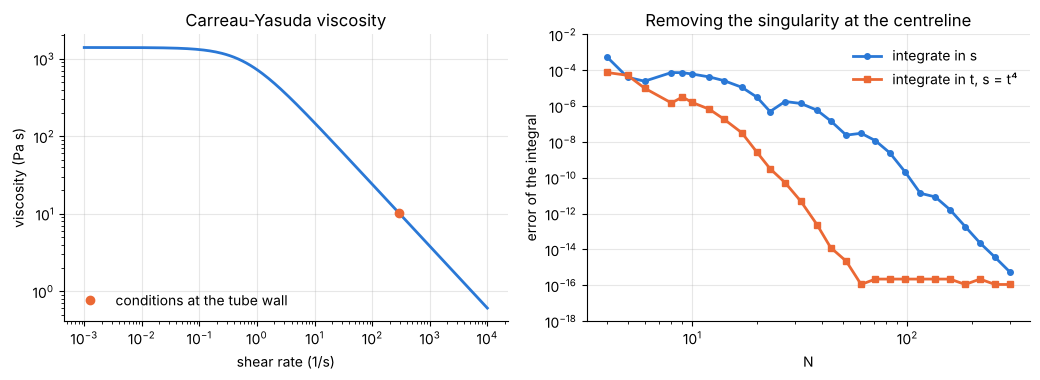

In [18]:
reference = reduced_integral(200, substitute=True)
N_values = np.unique(np.round(np.geomspace(4, 300, 28)).astype(int))
error_s = np.array([abs(reduced_integral(N, False) - reference) for N in N_values])
error_t = np.array([abs(reduced_integral(N, True) - reference) for N in N_values])

shear = np.geomspace(1e-3, 1e4, 200)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
axes[0].loglog(shear, viscosity(shear))
axes[0].plot(gamma_wall, viscosity(gamma_wall), "o", color="#eb6834", label="conditions at the tube wall")
axes[0].set(xlabel="shear rate (1/s)", ylabel="viscosity (Pa s)", title="Carreau-Yasuda viscosity")
axes[0].legend(frameon=False, loc="lower left")
axes[1].loglog(N_values, np.maximum(error_s, 1e-17), "o-", ms=4, label="integrate in s")
axes[1].loglog(N_values, np.maximum(error_t, 1e-17), "s-", ms=4, label="integrate in t, s = t⁴")
axes[1].set(xlabel="N", ylabel="error of the integral", ylim=(1e-18, 1e-2), title="Removing the singularity at the centreline")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()

**Verify**: the Newtonian limit, the convergence of both forms, self-convergence, and the
published numbers.

In [19]:
s, w = cc_on(4, 0.0, 1.0)
assert abs(w @ s**3 - 1 / 4) < 1e-15                               # Newtonian fluid: η_t = 1

tail = (N_values >= 70) & (N_values <= 180)
order_s = -np.polyfit(np.log(N_values[tail]), np.log(error_s[tail]), 1)[0]
at_32 = N_values == 32
print(f"N = 32: error {error_s[at_32][0]:.1e} in s,  {error_t[at_32][0]:.1e} in t.   Order of convergence in s for N > 70: {order_s:.1f}")
assert error_t[at_32][0] < 1e-10 < 1e-7 < error_s[at_32][0] and 8 < order_s < 13

u_mean = R_tube * gamma_wall / 3 * (1 - reduced_integral(48, substitute=True))
u_mean_finer = R_tube * gamma_wall / 3 * (1 - reduced_integral(96, substitute=True))
flow_rate = np.pi * R_tube**2 * u_mean
print(f"mean velocity {u_mean:.6f} m/s    flow rate {flow_rate:.6e} m³/s")
assert abs(u_mean / u_mean_finer - 1) < 1e-10                      # self-convergence
assert round(gamma_wall, 1) == 296.5                               # published: 296.5 1/s
assert round(u_mean, 3) == 0.372                                   # published: 0.372 m/s
assert round(flow_rate * 1e4, 3) == 1.169                          # published: 1.169e-4 m³/s

N = 32: error 1.4e-06 in s,  4.8e-12 in t.   Order of convergence in s for N > 70: 11.4
mean velocity 0.372216 m/s    flow rate 1.169352e-04 m³/s


The computed wall shear rate, mean velocity and flow rate, 296.5 s⁻¹, 0.372 m/s and
$1.169\times10^{-4}$ m³/s, agree with the published values to every quoted digit.

The convergence plot has a story in it. Integrated in $s$, the rule gains little until $N$
reaches about 40 and then converges algebraically, at an observed order of about 11. The
integrand is $s^3$ times a function of $s^{1.25}$, so its singular part behaves like
$s^{4.25}$, for which the rule of 10.7 predicts the order $2\times4.25 + 2 = 10.5$. The slow start has a
physical cause: at the wall $\lambda\dot\gamma_w \approx 470$, so the fluid is Newtonian only
for $s$ below about 0.002 (roughly the inner fifth of the radius), and the grid in $s$ must
resolve that narrow range before it can converge. In the variable $t$ the same transition sits at
$t \approx 0.2$ and 33 points give eleven digits.

For the engineer: at this pressure gradient the viscosity at the wall is 10 Pa s, a hundred
and forty times lower than the zero-shear value. A Newtonian estimate with $\eta_0$ would give
$\bar u = GR^2/(8\eta_0) = 0.0054$ m/s and underestimate the flow rate by a factor of 70.

## Summary

- Integrating the interpolant gives a quadrature rule with the accuracy of the interpolant.
- For a periodic integrand over a full period that rule is the trapezoidal rule with equal
  weights, and it converges geometrically.
- `clenshaw_curtis(N)` gives the weights for the Chebyshev points in one cosine transform.
  `gauss_legendre(n)` is exact to twice the degree. For integrands of limited smoothness the
  two rules are nearly equally accurate; for analytic ones Clenshaw-Curtis keeps pace to
  moderate accuracy and then converges at about half the rate.
- Scale the weights by $(b-a)/2$ for another interval and multiply them for a rectangle. A
  running integral is the boundary value problem $u' = f$.
- An end-point singularity reduces every one of these rules to algebraic convergence. A change
  of variable that makes the integrand smooth restores the spectral rate.

## Exercises

1. The period of a pendulum released from rest at the angle $\theta_0$ is
   $T/T_0 = \dfrac{2}{\pi}\displaystyle\int_0^{\pi/2}\frac{d\varphi}{\sqrt{1 - k^2\sin^2\varphi}}$
   with $k = \sin(\theta_0/2)$, where $T_0$ is the small-amplitude period. The integrand has
   period $\pi$, so $T/T_0$ is the mean of the integrand over $[0, \pi)$. Compute it with the
   periodic trapezoidal rule for $\theta_0 = 90°$ and $\theta_0 = 170°$, and find the smallest
   $N$ that gives ten correct digits in each case (check with `scipy.special.ellipk(k**2)`).
   Why does the larger amplitude need more points?
2. The fraction of black-body radiation emitted between the wavelengths $\lambda_1$ and
   $\lambda_2$ is $F = \dfrac{15}{\pi^4}\displaystyle\int_{x_2}^{x_1}\frac{x^3}{e^x - 1}\,dx$ with
   $x_i = c_2/(\lambda_iT)$ and $c_2 = 14388$ μm K. For the sun, $T = 5800$ K, compute the
   fraction emitted in the visible band from 0.4 μm to 0.7 μm with Clenshaw-Curtis and with
   Gauss-Legendre, and find how many points each rule needs for an error below $10^{-10}$.
3. The laminar velocity profile of a power-law fluid in a tube is
   $u/u_{\max} = 1 - r^{(n+1)/n}$, with mean-to-maximum ratio $(n+1)/(3n+1)$. For $n = 0.4$
   compute $2\int_0^1u\,r\,dr$ with Clenshaw-Curtis for $N = 8, 12, 16, 20, 24$ and measure the
   order of convergence. Compare it with the prediction of 10.7. Then find a substitution that
   makes the integrand a polynomial and confirm that the rule becomes exact.
4. The Einstein model of a solid gives the heat capacity
   $c_v/(3R) = y^2e^{y}/(e^{y} - 1)^2$ with $y = \Theta/T$. For $\Theta = 400$ K use
   `running_integral`, mapped to the interval from 100 K to 1000 K with $N = 32$, to compute
   the energy $\int_{100}^{T}c_v\,dT'/(3R)$ at every grid temperature. Compare with the exact
   result $\Theta/(e^{\Theta/T} - 1) - \Theta/(e^{\Theta/100} - 1)$ and report the largest error.
5. The radiation view factor between two directly opposed parallel unit squares a distance
   $h = 1$ apart is the four-dimensional integral
   $F_{12} = \displaystyle\int_0^1\!\!\int_0^1\!\!\int_0^1\!\!\int_0^1\frac{h^2}{\pi\,\big[(x_1-x_2)^2 + (y_1-y_2)^2 + h^2\big]^2}\,dx_1\,dy_1\,dx_2\,dy_2 .$
   Evaluate it with a tensor product of four Clenshaw-Curtis rules with $N = 16$ in each
   direction. The tabulated value is 0.1998.